# Checkpoint 5: Narrative Analysis

This notebook produces every number and figure in the **Main Findings** section of the repository `README.md`. Longer
notes on the checks are in [`NARRATIVE.md`](NARRATIVE.md). The analysis code is adapted from
`notebooks/personal_notebooks/dev3.ipynb` (the exploratory notebook). This notebook keeps only what the three findings need.

| Finding | Research question | Starting visual in dev3 | Main analysis |
|---|---|---|---|
| 1. Mapping spread to new counties early, then filled in | Q1: where are mapped cameras, and how has mapping grown? | V2 (growth), V3 (states) | monthly counts, cumulative cameras vs cumulative counties |
| 2. Whiter places have fewer mapped cameras per resident | Q2: is density associated with community characteristics? | V5 (race / poverty), V4 (income) | tract quintiles + county negative binomial (NB2) regression |
| 3. Vote share has little association once other factors are held fixed | Q3: is density associated with voting patterns? | V8 (scatter + regression) | unadjusted vs adjusted NB2 regressions (plus dev3's OLS) |

**Ground rules.** All counts are cameras *mapped* in OpenStreetMap (OSM), not all installed cameras. OSM dates are
mapping dates, not installation dates. Every result is an observational association.

**Professor's feedback.** The county regression follows the suggested model
`flock_count ~ log_pop + log_income + poverty_rate + urban_share + gop_share_2024 + C(state)` with offset
`log(land_sq_mi)`, fitted as a negative binomial (NB2) with the dispersion estimated by maximum likelihood. The repo has
no urban/rural data, so `urban_share` is left out (see Finding 2). We also test whether the land-area offset fits the data.

Run from top to bottom in the project environment (`uv sync`, then select the `.venv` kernel). It needs the raw files
in `data/raw/` and `data/external/`, and it writes three PNGs to `figures/`.

In [1]:
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.optimize import minimize_scalar
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=UserWarning, message=".*(CRS|crs|pyproj|geographic).*")
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(200)

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#898781", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
    "xtick.labelsize": 10.5, "ytick.labelsize": 10.5, "legend.fontsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from cs418_flock_research.loaders.load_osm_history import load_osm_history
from cs418_flock_research.loaders.load_osm_locations import load_osm_locations

RAW, EXT = ROOT / "data" / "raw", ROOT / "data" / "external"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
P = {
    "locations": RAW / "flock_osm" / "osm_flock_us_locations_2026-10-30.csv",
    "history": RAW / "flock_osm" / "flock_us_historical_2026-10-30.csv",
    "ff_state": RAW / "finding_flock" / "findingflock-cameras-by-state.csv",
    "acs_pop": RAW / "census" / "population" / "2024" / "ACSDT5Y2024.B01003-Data.csv",
    "acs_income": RAW / "census" / "median_household_income" / "2024" / "ACSDT5Y2024.B19013-Data.csv",
    "acs_poverty": RAW / "census" / "poverty" / "2024" / "ACSST5Y2024.S1701-Data.csv",
    "acs_race": RAW / "census" / "race_ethnicity" / "2024" / "ACSDT5Y2024.B03002-Data.csv",
    "elections": RAW / "elections" / "presidential" / "countypres_2000-2024.csv",
    "tracts_2024": EXT / "census_boundaries" / "2024",
    "ct_tracts_2017": EXT / "census_boundaries" / "2017" / "tl_2017_09_tract.zip",
    "counties": EXT / "census_boundaries" / "counties" / "tl_2024_us_county.zip",
}
missing = [k for k, v in P.items() if not v.exists()]
assert not missing, f"missing inputs: {missing}"
print("root:", ROOT)

root: C:\Users\awaid\OneDrive\Desktop\D\UIC\UIC_Fa26\CS418\cs418-flock-research


In [2]:
# --- shared helpers (same definitions as dev3) --------------------------------------------------------------------
STATES = {
    "01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA", "08": "CO", "09": "CT", "10": "DE", "11": "DC", "12": "FL",
    "13": "GA", "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA", "20": "KS", "21": "KY", "22": "LA", "23": "ME",
    "24": "MD", "25": "MA", "26": "MI", "27": "MN", "28": "MS", "29": "MO", "30": "MT", "31": "NE", "32": "NV", "33": "NH",
    "34": "NJ", "35": "NM", "36": "NY", "37": "NC", "38": "ND", "39": "OH", "40": "OK", "41": "OR", "42": "PA", "44": "RI",
    "45": "SC", "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT", "51": "VA", "53": "WA", "54": "WV", "55": "WI",
    "56": "WY", "60": "AS", "66": "GU", "69": "MP", "72": "PR", "78": "VI",
}
STATE_DF = pl.DataFrame({"STATEFP": list(STATES), "state": list(STATES.values())})


def acs_number(col: str) -> pl.Expr:
    # ACS text -> float. '250,000+' -> 250001, '2,500-' -> 2499, '-', '**', '(X)' -> null.
    s = pl.col(col).str.replace_all(",", "")
    return (pl.when(s.str.ends_with("+")).then(s.str.strip_suffix("+").cast(pl.Float64, strict=False) + 1)
            .when(s.str.ends_with("-") & (s.str.len_chars() > 1)).then(s.str.strip_suffix("-").cast(pl.Float64, strict=False) - 1)
            .otherwise(s.cast(pl.Float64, strict=False)).alias(col))


def read_acs(path: Path, cols: list[str]) -> pl.DataFrame:
    # data.census.gov download: row 0 repeats the labels; GEO_ID = '1400000US' + 11-digit tract GEOID.
    df = pl.read_csv(path, infer_schema_length=0, columns=["GEO_ID", *cols]).slice(1)
    df = df.with_columns(pl.col("GEO_ID").str.slice(9).alias("GEOID")).drop("GEO_ID")
    return df.with_columns([acs_number(c) for c in cols])


def assign_polygons(points: pl.DataFrame, polys: gpd.GeoDataFrame, keep: list[str], max_deg: float = 0.03) -> pl.DataFrame:
    # Point-in-polygon in lon/lat; points outside every polygon go to the nearest one within max_deg (~2-3 km).
    pts = gpd.GeoDataFrame(points.select("osm_id").to_pandas(),
                           geometry=gpd.points_from_xy(points["lon"].to_numpy(), points["lat"].to_numpy()), crs=polys.crs)
    polys = polys[keep + ["geometry"]]
    hit = gpd.sjoin(pts, polys, how="inner", predicate="within").drop_duplicates("osm_id")
    rest = pts[~pts["osm_id"].isin(hit["osm_id"])]
    near = gpd.sjoin_nearest(rest, polys, how="inner", max_distance=max_deg).drop_duplicates("osm_id")
    out = pd.concat([hit, near])[["osm_id", *keep]]
    return points.select("osm_id").join(pl.from_pandas(out), on="osm_id", how="left")


def pooled_rate(cams: np.ndarray, pop: np.ndarray, reps: int = 1000, seed: int = 418):
    # All cameras / all residents * 10,000, with a 95% bootstrap interval (resampling units with replacement).
    rng = np.random.default_rng(seed)
    est, boots = cams.sum() / pop.sum() * 1e4, []
    for _ in range(reps // 100):
        idx = rng.integers(0, len(cams), (100, len(cams)))
        boots.append(cams[idx].sum(1) / pop[idx].sum(1) * 1e4)
    lo, hi = np.percentile(np.concatenate(boots), [2.5, 97.5])
    return est, lo, hi


def manufacturer_status(manufacturer, brand=None) -> str:
    # dev3 rule: strings naming a second vendor are 'ambiguous' and are not counted as Flock.
    if manufacturer is None:
        return "missing"
    low = manufacturer.casefold().strip()
    if ";" in low or any(v in low for v in ("motorola", "platesmart", "genetec", "vigilant")):
        return "ambiguous"
    if brand is not None and "flock" not in brand.casefold():
        return "ambiguous"
    if low.replace(" ", "") in {"flocksafety", "flock", "flockgroupinc.", "flockgroupinc", "flocksafetyinc", "flocksafetyinc."}:
        return "exact"
    return "annotated" if low.startswith("flock safety") else "ambiguous"


def add_is_flock(df: pl.DataFrame, brand_col: str | None) -> pl.DataFrame:
    cols = ["manufacturer"] + ([brand_col] if brand_col else [])
    pairs = df.select(cols).unique()
    pairs = pairs.with_columns(pl.Series("is_flock", [
        manufacturer_status(r["manufacturer"], r.get(brand_col) if brand_col else None) != "ambiguous"
        for r in pairs.iter_rows(named=True)]))
    return df.join(pairs, on=cols, how="left", nulls_equal=True)


RESULTS = {}  # every number quoted in the README is stored here and printed at the end

## Load the shared inputs

The OSM snapshot gives one row per mapped camera (used for the counts). Each camera is assigned a county and state
from the TIGER 2024 county file.

In [3]:
snap = add_is_flock(load_osm_locations(P["locations"]), "brand")
flock = snap.filter("is_flock")
counties = gpd.read_file(f"zip://{P['counties'].as_posix()}", columns=["STATEFP", "GEOID", "NAME", "ALAND"])
cty = assign_polygons(flock, counties.rename(columns={"GEOID": "county_geoid"}), ["STATEFP", "county_geoid"])
flock = flock.join(cty, on="osm_id", how="left").join(STATE_DF, on="STATEFP", how="left")
assert flock["state"].null_count() == 0
print(f"snapshot rows {snap.height:,} | counted as Flock {flock.height:,} | without a state {flock['state'].null_count()}")

acs_pop = read_acs(P["acs_pop"], ["B01003_001E"]).rename({"B01003_001E": "population"})

snapshot rows 112,830 | counted as Flock 112,823 | without a state 0


---
## Finding 1: Mapping growth (Q1)

**Question.** Where are mapped cameras concentrated, and does the OSM growth curve show deployment or mapping?

**Analysis.** For every camera in the history file, we take the month it was first tagged as a Flock ALPR
(`first_tagged_date`). For each month we count new cameras, the OSM changesets (upload batches) they arrived in, and
how many were re-tags of objects that already existed. To separate *more cameras* from *more places*, we also track the
cumulative number of distinct counties that contain at least one mapped camera. Geography is checked with state totals
against population and against Finding Flock, a separate crowdsourced count.

ZIP codes are not used: the repo has no ZCTA (ZIP) boundary file, so cameras cannot be placed in ZIP areas reliably.

In [4]:
TS = "%Y-%m-%dT%H:%M:%S%.f%z"
hist = load_osm_history(P["history"]).with_columns(
    [pl.col(c).str.to_datetime(TS).dt.convert_time_zone("UTC") for c in ["first_insert_date", "first_tagged_date", "last_edit"]])
hist = add_is_flock(hist, None).filter("is_flock")

# Changeset size = how many cameras in this cohort were first Flock-tagged in the same upload.
hist = (hist.join(hist.group_by("first_tagged_changeset").len("changeset_size"), on="first_tagged_changeset")
            .with_columns(pl.col("first_tagged_date").dt.truncate("1mo").dt.date().alias("month"),
                          (pl.col("first_tagged_version") > 1).alias("retag"),
                          (pl.col("changeset_size") >= 50).alias("bulk")))

monthly = (hist.group_by("month").agg(
               pl.len().alias("new"),
               pl.col("bulk").sum().alias("in_bulk_changesets"),
               pl.col("retag").mean().alias("retag_share"),
               pl.col("first_tagged_changeset").n_unique().alias("changesets"),
               # 'user' is the last editor; for nodes still at version 1 that is the person who mapped the camera.
               pl.col("user").filter(pl.col("version") == 1).n_unique().alias("contributors_v1"))
           .sort("month").with_columns(pl.col("new").cum_sum().alias("cumulative"),
                                       (pl.col("new") / pl.col("changesets")).alias("cameras_per_changeset")))
assert monthly["cumulative"][-1] == hist.height
monthly.with_columns(pl.col("month").dt.strftime("%Y-%m"), pl.col("retag_share", "cameras_per_changeset").round(3))

month,new,in_bulk_changesets,retag_share,changesets,contributors_v1,cumulative,cameras_per_changeset
str,u32,u32,f64,u32,u32,u32,f64
"""2024-11""",514,430,0.053,24,2,514,21.417
"""2024-12""",787,0,0.072,403,60,1301,1.953
"""2025-01""",1856,0,0.046,974,109,3157,1.906
"""2025-02""",1421,291,0.027,610,97,4578,2.33
"""2025-03""",1438,0,0.088,872,123,6016,1.649
"""2025-04""",2401,0,0.105,1196,134,8417,2.008
"""2025-05""",1767,59,0.065,998,141,10184,1.771
"""2025-06""",1955,101,0.075,1033,183,12139,1.893
"""2025-07""",1765,0,0.062,1026,179,13904,1.72


In [5]:
y26 = hist.filter(pl.col("first_tagged_date").dt.year() == 2026)
peak = monthly.filter(pl.col("month").dt.year() == 2026).sort("new", descending=True).head(2).sort("month")
pre = monthly.filter(pl.col("month") <= pl.date(2025, 6, 1))
burst = hist.filter(pl.col("month").is_in(peak["month"].implode()))

RESULTS["f1_total_dated"] = hist.height
RESULTS["f1_first_month"] = str(monthly["month"][0])
RESULTS["f1_first_month_new"] = int(monthly["new"][0])
RESULTS["f1_2026_new"] = y26.height
RESULTS["f1_2026_share"] = y26.height / hist.height
RESULTS["f1_jun2025_cumulative"] = int(pre["cumulative"][-1])
RESULTS["f1_pre_monthly_range"] = (int(pre["new"].min()), int(pre["new"].max()))
RESULTS["f1_peak_months"] = [(str(m), int(n)) for m, n in peak.select("month", "new").iter_rows()]
RESULTS["f1_peak_total"] = int(peak["new"].sum())
RESULTS["f1_peak_changesets"] = burst["first_tagged_changeset"].n_unique()
RESULTS["f1_peak_contributors_v1"] = burst.filter(pl.col("version") == 1)["user"].n_unique()
RESULTS["f1_peak_retag_share"] = burst["retag"].mean()
RESULTS["f1_peak_bulk_share"] = burst["bulk"].mean()
RESULTS["f1_all_bulk_share"] = hist["bulk"].mean()
RESULTS["f1_all_retag_share"] = hist["retag"].mean()
RESULTS["f1_max_changeset"] = int(hist["changeset_size"].max())
for k in [k for k in RESULTS if k.startswith("f1_")]:
    print(f"{k:28s} {RESULTS[k]}")

f1_total_dated               112522
f1_first_month               2024-11-01
f1_first_month_new           514
f1_2026_new                  68899
f1_2026_share                0.6123158137964132
f1_jun2025_cumulative        12139
f1_pre_monthly_range         (514, 2401)
f1_peak_months               [('2026-07-01', 11457), ('2026-08-01', 11807)]
f1_peak_total                23264
f1_peak_changesets           22599
f1_peak_contributors_v1      9243
f1_peak_retag_share          0.013970082530949106
f1_peak_bulk_share           0.0
f1_all_bulk_share            0.010966744281118358
f1_all_retag_share           0.03444659710989851
f1_max_changeset             430


**Alternative explanation A: the bursts are an artifact of bulk imports or re-tagging.** If one editor re-tagged
thousands of existing objects, or imported a dataset, the bursts would sit in a few large changesets and be mostly
re-tags. The check is the changeset-size and re-tag shares above, plus where the curve starts.

In [6]:
# Where does the curve start? Objects created before Nov 2024 only reach the current tagging rule later.
CUTOFF = pl.datetime(2024, 11, 1, time_zone="UTC")
early = hist.filter(pl.col("first_insert_date") < CUTOFF)
RESULTS["f1_earliest_tag"] = str(hist["first_tagged_date"].min().date())
RESULTS["f1_created_before_nov2024"] = early.height
RESULTS["f1_created_before_and_tagged_later"] = early.filter(pl.col("first_tagged_version") > 1).height
print("earliest first-tagged date           :", RESULTS["f1_earliest_tag"])
print("nodes created before Nov 2024        :", RESULTS["f1_created_before_nov2024"],
      "| of these, Flock-tagged in a later version:", RESULTS["f1_created_before_and_tagged_later"])
print("months containing a >= 50-camera changeset:",
      monthly.filter(pl.col("in_bulk_changesets") > 0).select(pl.col("month").dt.strftime("%Y-%m"), "in_bulk_changesets").rows())

earliest first-tagged date           : 2024-11-03
nodes created before Nov 2024        : 657 | of these, Flock-tagged in a later version: 657
months containing a >= 50-camera changeset: [('2024-11', 430), ('2025-02', 291), ('2025-05', 59), ('2025-06', 101), ('2025-09', 178), ('2025-10', 69), ('2026-04', 106)]


**More cameras or more places? (second growth measure).** Each dated camera is placed in a TIGER 2024 county. A county
counts as "reached" in the month its first camera was tagged. If the 2026 surge were mainly mapping spreading into new
areas, the county curve would rise as steeply as the camera curve. If it were mainly filling in, the county curve would
flatten first.

**Third measure (object creation date).** `first_insert_date` is when the OSM object was first created, whatever its
tags. Using it instead of the tagging date checks that the 2026 surge is not a tag-change artifact.

In [7]:
hc = assign_polygons(hist, counties.rename(columns={"GEOID": "county_geoid"}), ["county_geoid"])
hist = hist.join(hc, on="osm_id", how="left")
assert hist["county_geoid"].null_count() == 0
reached = hist.group_by("county_geoid").agg(pl.col("month").min().alias("month_reached"))
spread = (monthly.select("month", "cumulative")
                 .join(reached.group_by("month_reached").len("new_counties"), left_on="month", right_on="month_reached", how="left")
                 .with_columns(pl.col("new_counties").fill_null(0).cum_sum().alias("counties_reached"))
                 .with_columns((pl.col("cumulative") / pl.col("cumulative").max()).alias("cameras_share"),
                               (pl.col("counties_reached") / pl.col("counties_reached").max()).alias("counties_share")))
end25 = spread.filter(pl.col("month") == pl.date(2025, 12, 1)).row(0, named=True)
y26 = hist.filter(pl.col("first_tagged_date").dt.year() == 2026).join(reached, on="county_geoid", how="left")
RESULTS["f1_counties_reached"] = reached.height
RESULTS["f1_end2025_counties_share"] = end25["counties_share"]
RESULTS["f1_end2025_cameras_share"] = end25["cameras_share"]
RESULTS["f1_2026_in_already_mapped_counties"] = y26.select((pl.col("month_reached") < pl.date(2026, 1, 1)).mean()).item()
RESULTS["f1_2026_share_by_insert_date"] = (hist["first_insert_date"].dt.year() == 2026).mean()
RESULTS["f1_2026_share_by_tag_date"] = RESULTS["f1_2026_share"]
for k in ["f1_counties_reached", "f1_end2025_counties_share", "f1_end2025_cameras_share",
          "f1_2026_in_already_mapped_counties", "f1_2026_share_by_tag_date", "f1_2026_share_by_insert_date"]:
    print(f"{k:36s} {RESULTS[k]}")
spread.with_columns(pl.col("month").dt.strftime("%Y-%m"), pl.col("cameras_share", "counties_share").round(3))

f1_counties_reached                  2279
f1_end2025_counties_share            0.6739798157086442
f1_end2025_cameras_share             0.38768418620358686
f1_2026_in_already_mapped_counties   0.9403910071263734
f1_2026_share_by_tag_date            0.6123158137964132
f1_2026_share_by_insert_date         0.6007447432502089


month,cumulative,new_counties,counties_reached,cameras_share,counties_share
str,u32,u32,u32,f64,f64
"""2024-11""",514,2,2,0.005,0.001
"""2024-12""",1301,109,111,0.012,0.049
"""2025-01""",3157,153,264,0.028,0.116
"""2025-02""",4578,83,347,0.041,0.152
"""2025-03""",6016,106,453,0.053,0.199
"""2025-04""",8417,76,529,0.075,0.232
"""2025-05""",10184,80,609,0.091,0.267
"""2025-06""",12139,83,692,0.108,0.304
"""2025-07""",13904,88,780,0.124,0.342


**Alternative explanation B: the mapped geography does not reflect real deployments, only where volunteers are
active.** Check: compare state totals with population and with Finding Flock's independent state counts (all ALPR
vendors). Spearman correlations come with a 95% bootstrap interval over states.

In [8]:
state_pop = acs_pop.group_by(pl.col("GEOID").str.slice(0, 2).alias("STATEFP")).agg(pl.col("population").sum())
ff = pl.read_csv(P["ff_state"]).select("state", pl.col("cameras_statewide").alias("ff_all_vendors"))
by_state = (flock.group_by("STATEFP", "state").len("cameras")
                 .join(state_pop, on="STATEFP", how="left").join(ff, on="state", how="left")
                 .with_columns((pl.col("cameras") / pl.col("population") * 1e5).alias("per_100k")))


def spearman_ci(x, y, reps=2000, seed=418):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    boots = [stats.spearmanr(x[i], y[i]).statistic for i in (rng.integers(0, len(x), len(x)) for _ in range(reps))]
    return stats.spearmanr(x, y).statistic, *np.percentile(boots, [2.5, 97.5])


sp = by_state.drop_nulls("population")
ffm = by_state.drop_nulls("ff_all_vendors")
top5 = by_state.sort("cameras", descending=True).head(5)
RESULTS["f1_top5_states"] = top5["state"].to_list()
RESULTS["f1_top5_share"] = top5["cameras"].sum() / flock.height
RESULTS["f1_rho_pop"] = spearman_ci(sp["cameras"], sp["population"])
RESULTS["f1_rho_ff"] = spearman_ci(ffm["cameras"], ffm["ff_all_vendors"])
RESULTS["f1_osm_over_ff"] = ffm["cameras"].sum() / ffm["ff_all_vendors"].sum()
RESULTS["f1_median_state_per_100k"] = sp["per_100k"].median()
ga = by_state.filter(pl.col("state") == "GA").row(0, named=True)
RESULTS["f1_ga_per_100k"] = ga["per_100k"]
print(f"top 5 states {RESULTS['f1_top5_states']} hold {RESULTS['f1_top5_share']:.1%} of mapped cameras")
print("Spearman rho, state cameras vs population (rho, 95% CI): ", np.round(RESULTS["f1_rho_pop"], 2), f"n = {sp.height}")
print("Spearman rho, OSM Flock vs Finding Flock all-vendor:      ", np.round(RESULTS["f1_rho_ff"], 3), f"n = {ffm.height}")
print(f"OSM Flock / Finding Flock all-vendor total: {RESULTS['f1_osm_over_ff']:.2f}")
print(f"median state {RESULTS['f1_median_state_per_100k']:.1f} per 100k | Georgia {RESULTS['f1_ga_per_100k']:.1f} per 100k")

top 5 states ['CA', 'TX', 'GA', 'FL', 'OH'] hold 48.6% of mapped cameras
Spearman rho, state cameras vs population (rho, 95% CI):  [0.89 0.81 0.93] n = 52
Spearman rho, OSM Flock vs Finding Flock all-vendor:       [0.976 0.935 0.993] n = 52
OSM Flock / Finding Flock all-vendor total: 0.78
median state 26.6 per 100k | Georgia 85.0 per 100k


### Figure 1

The bars split each month's new cameras into those uploaded in large changesets (50 or more cameras in one upload)
and everything else. The bottom panel compares the two cumulative measures, each as a share of its October 2026 total.

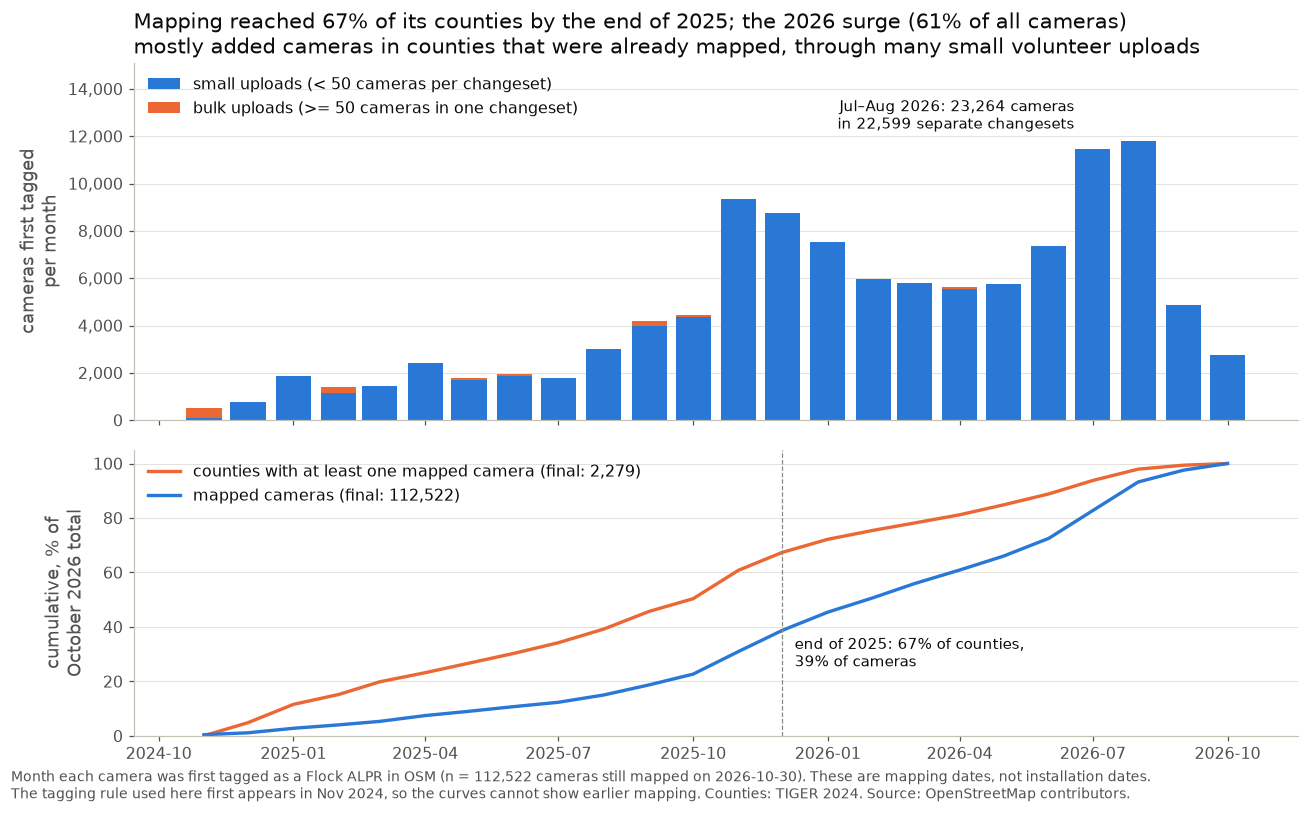

In [9]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7.2), sharex=True, gridspec_kw={"height_ratios": [1.25, 1]})
m = monthly["month"].to_list()
small = (monthly["new"] - monthly["in_bulk_changesets"]).to_numpy()
a1.bar(m, small, width=24, color=BLUE, zorder=2, label="small uploads (< 50 cameras per changeset)")
a1.bar(m, monthly["in_bulk_changesets"].to_numpy(), bottom=small, width=24, color=ORANGE, zorder=2,
       label="bulk uploads (>= 50 cameras in one changeset)")
a1.annotate(f"Jul–Aug 2026: {RESULTS['f1_peak_total']:,} cameras\nin {RESULTS['f1_peak_changesets']:,} separate changesets",
            (peak["month"][0], peak["new"].max()), xytext=(-12, 8), textcoords="offset points", ha="right", fontsize=9.5, color=INK)
a1.set_ylabel("cameras first tagged\nper month")
a1.set_ylim(0, monthly["new"].max() * 1.28)
a1.legend(loc="upper left", frameon=False)
assert RESULTS["f1_end2025_counties_share"] > 0.5 and RESULTS["f1_2026_in_already_mapped_counties"] > 0.5  # title claims
sm_ = spread["month"].to_list()
a2.plot(sm_, spread["counties_share"] * 100, color=ORANGE, linewidth=2.2,
        label=f"counties with at least one mapped camera (final: {RESULTS['f1_counties_reached']:,})")
a2.plot(sm_, spread["cameras_share"] * 100, color=BLUE, linewidth=2.2,
        label=f"mapped cameras (final: {hist.height:,})")
dec = pd.Timestamp(2025, 12, 1)
a2.axvline(dec, color=GREY, linewidth=0.8, linestyle="--")
a2.annotate(f"end of 2025: {RESULTS['f1_end2025_counties_share']:.0%} of counties,\n"
            f"{RESULTS['f1_end2025_cameras_share']:.0%} of cameras", (dec, RESULTS["f1_end2025_cameras_share"] * 100),
            xytext=(8, -4), textcoords="offset points", fontsize=9.5, color=INK, va="top")
a2.set_ylabel("cumulative, % of\nOctober 2026 total")
a2.set_ylim(0, 105)
a2.legend(loc="upper left", frameon=False)
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
for a in (a1, a2):
    a.grid(axis="x", visible=False)
a1.set_title(f"Mapping reached {RESULTS['f1_end2025_counties_share']:.0%} of its counties by the end of 2025; the 2026 surge "
             f"({RESULTS['f1_2026_share']:.0%} of all cameras)\nmostly added cameras in counties that were already mapped, "
             "through many small volunteer uploads", loc="left", fontsize=13.5)
fig.text(0.01, -0.02, f"Month each camera was first tagged as a Flock ALPR in OSM (n = {hist.height:,} cameras still mapped on "
         "2026-10-30). These are mapping dates, not installation dates.\nThe tagging rule used here first appears in Nov 2024, "
         "so the curves cannot show earlier mapping. Counties: TIGER 2024. Source: OpenStreetMap contributors.", color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "finding-one.png", bbox_inches="tight")
plt.show()

---
## Finding 2: Community demographics (Q2)

**Question.** Is mapped camera density associated with a neighbourhood's racial or economic makeup?

**Analysis.** We build one row per census tract (TIGER 2024 boundaries, ACS 2024 5-year estimates) and keep tracts
with zero cameras. Tracts are split into national quintiles of % non-Hispanic white residents, poverty rate and median
income. Each group's density is pooled (all cameras ÷ all residents × 10,000), with 95% bootstrap intervals over tracts.

In [10]:
tract_files = sorted(P["tracts_2024"].glob("tl_2024_*_tract.zip"))
tracts_geo = gpd.GeoDataFrame(pd.concat([gpd.read_file(f"zip://{f.as_posix()}", columns=["GEOID", "STATEFP", "COUNTYFP", "ALAND"])
                                         for f in tract_files], ignore_index=True), geometry="geometry", crs=counties.crs)

income = read_acs(P["acs_income"], ["B19013_001E"]).rename({"B19013_001E": "median_income"})
poverty = read_acs(P["acs_poverty"], ["S1701_C03_001E"]).rename({"S1701_C03_001E": "pct_poverty"})
race = (read_acs(P["acs_race"], ["B03002_001E", "B03002_003E"])
        .with_columns((pl.col("B03002_003E") / pl.col("B03002_001E") * 100).alias("pct_nh_white")).select("GEOID", "pct_nh_white"))
acs = acs_pop.join(income, on="GEOID").join(poverty, on="GEOID").join(race, on="GEOID")

cam_tract = assign_polygons(flock, tracts_geo, ["GEOID"])
tract = (pl.from_pandas(pd.DataFrame(tracts_geo.drop(columns="geometry")))
           .join(STATE_DF, on="STATEFP", how="left").join(acs, on="GEOID", how="left")
           .join(cam_tract.drop_nulls("GEOID").group_by("GEOID").len("cameras"), on="GEOID", how="left")
           .with_columns(pl.col("cameras").fill_null(0), (pl.col("ALAND") / 1e6).alias("land_km2"))
           .with_columns(pl.when(pl.col("population") > 0).then(pl.col("cameras") / pl.col("population") * 1e4).alias("cameras_per_10k")))

# Same eligibility as dev3 V4/V5: ACS estimates present, an income estimate, and at least one resident.
elig = tract.filter(pl.col("population").is_not_null() & pl.col("median_income").is_not_null() & (pl.col("population") > 0))
print(f"tracts {tract.height:,} | analysed {elig.height:,} (zero-camera {int((elig['cameras'] == 0).sum()):,}) | "
      f"cameras in analysed tracts {int(elig['cameras'].sum()):,} of {flock.height:,}")
print("not in any tract (no PR / USVI tract boundaries in repo):", cam_tract["GEOID"].null_count())

tracts 84,415 | analysed 82,913 (zero-camera 47,912) | cameras in analysed tracts 111,382 of 112,823
not in any tract (no PR / USVI tract boundaries in repo): 204


In [11]:
def quintile(col: str, over: str | None = None) -> pl.Expr:
    # 1 = lowest fifth of tracts on `col`, 5 = highest; ranked nationally, or within each `over` group.
    r, n = pl.col(col).rank("ordinal"), pl.len()
    if over:
        r, n = r.over(over), n.over(over)
    return ((r - 1) * 5 // n + 1).alias("q")


def pooled_table(df: pl.DataFrame, col: str, over: str | None = None) -> pl.DataFrame:
    df = df.drop_nulls(col).with_columns(quintile(col, over))
    rows = []
    for q in range(1, 6):
        g = df.filter(pl.col("q") == q)
        est, lo, hi = pooled_rate(g["cameras"].to_numpy(), g["population"].to_numpy())
        rows.append({"q": q, "tracts": g.height, "min": g[col].min(), "max": g[col].max(), "cameras": int(g["cameras"].sum()),
                     "per_10k": est, "ci_lo": lo, "ci_hi": hi, "share_with_camera": (g["cameras"] > 0).mean()})
    return pl.DataFrame(rows)


race_nat = pooled_table(elig, "pct_nh_white")
race_ws = pooled_table(elig, "pct_nh_white", over="state")
pov_nat = pooled_table(elig, "pct_poverty")
inc_nat = pooled_table(elig, "median_income")
show = lambda t, name: t.select(pl.lit(name).alias("by"), "q", "tracts", pl.col("min", "max").round(1),
                                pl.col("per_10k", "ci_lo", "ci_hi").round(2), pl.col("share_with_camera").round(3))
pl.concat([show(race_nat, "% NH white, national"), show(race_ws, "% NH white, within state"),
           show(pov_nat, "poverty, national"), show(inc_nat, "income, national")])

by,q,tracts,min,max,per_10k,ci_lo,ci_hi,share_with_camera
str,i64,i64,f64,f64,f64,f64,f64,f64
"""% NH white, national""",1,16583,0.0,27.4,3.35,3.25,3.45,0.418
"""% NH white, national""",2,16583,27.4,55.3,4.13,4.01,4.24,0.488
"""% NH white, national""",3,16582,55.3,73.4,3.63,3.53,3.73,0.453
"""% NH white, national""",4,16583,73.4,86.4,3.12,3.02,3.21,0.416
"""% NH white, national""",5,16582,86.4,100.0,2.33,2.25,2.4,0.337
"""% NH white, within state""",1,16604,0.0,87.0,3.19,3.08,3.28,0.407
"""% NH white, within state""",2,16581,6.5,91.0,3.72,3.62,3.83,0.452
"""% NH white, within state""",3,16584,12.9,93.7,3.63,3.54,3.73,0.452
"""% NH white, within state""",4,16581,21.0,96.7,3.18,3.09,3.27,0.422


In [12]:
rho = {name: stats.spearmanr(elig.drop_nulls(c)[c], elig.drop_nulls(c)["cameras_per_10k"])
       for name, c in [("pct_nh_white", "pct_nh_white"), ("pct_poverty", "pct_poverty"), ("median_income", "median_income")]}
q = {r["q"]: r for r in race_nat.iter_rows(named=True)}
w = {r["q"]: r for r in race_ws.iter_rows(named=True)}
peak_q = max(q, key=lambda k: q[k]["per_10k"])
RESULTS["f2_n_tracts"] = elig.height
RESULTS["f2_white_q5"] = (q[5]["per_10k"], q[5]["ci_lo"], q[5]["ci_hi"], q[5]["min"], q[5]["max"], q[5]["share_with_camera"])
RESULTS["f2_peak_q"] = (peak_q, q[peak_q]["per_10k"], q[peak_q]["ci_lo"], q[peak_q]["ci_hi"], q[peak_q]["min"], q[peak_q]["max"],
                        q[peak_q]["share_with_camera"])
RESULTS["f2_white_q1"] = (q[1]["per_10k"], q[1]["ci_lo"], q[1]["ci_hi"])
RESULTS["f2_q5_vs_peak_pct_lower"] = 1 - q[5]["per_10k"] / q[peak_q]["per_10k"]
RESULTS["f2_ws_q5"] = (w[5]["per_10k"], w[5]["ci_lo"], w[5]["ci_hi"])
RESULTS["f2_ws_peak"] = (max(w, key=lambda k: w[k]["per_10k"]), max(r["per_10k"] for r in w.values()))
RESULTS["f2_gap_national"] = q[peak_q]["per_10k"] - q[5]["per_10k"]
RESULTS["f2_gap_within_state"] = RESULTS["f2_ws_peak"][1] - w[5]["per_10k"]
RESULTS["f2_gap_remaining_share"] = RESULTS["f2_gap_within_state"] / RESULTS["f2_gap_national"]
RESULTS["f2_rho"] = {k: (round(v.statistic, 3), float(v.pvalue)) for k, v in rho.items()}
RESULTS["f2_poverty_q1_q5"] = (pov_nat["per_10k"][0], pov_nat["per_10k"][-1])
RESULTS["f2_income_range"] = (inc_nat["per_10k"].min(), inc_nat["per_10k"].max())
for k in [k for k in RESULTS if k.startswith("f2_")]:
    print(f"{k:26s} {RESULTS[k]}")

f2_n_tracts                82913
f2_white_q5                (2.3269195146203736, 2.254865177930614, 2.3998064496984846, 86.37104662536682, 100.0, 0.3365697744542275)
f2_peak_q                  (2, 4.132393650234935, 4.009961345342769, 4.240997026911486, 27.431566686080373, 55.28862195528862, 0.488150515588253)
f2_white_q1                (3.348272965180998, 3.2498632970953256, 3.451174326253441)
f2_q5_vs_peak_pct_lower    0.4369075863602482
f2_ws_q5                   (2.896976730372358, 2.8090718319451438, 2.9898625226995614)
f2_ws_peak                 (2, 3.7210276032153526)
f2_gap_national            1.8054741356145612
f2_gap_within_state        0.8240508728429945
f2_gap_remaining_share     0.4564179882657238
f2_rho                     {'pct_nh_white': (np.float64(-0.071), 1.8962336160808563e-93), 'pct_poverty': (np.float64(0.016), 4.827205538263007e-06), 'median_income': (np.float64(-0.028), 9.052141159815069e-16)}
f2_poverty_q1_q5           (3.1956490915772684, 3.6300988093968862)
f

**Alternative explanation A: urban vs rural.** White tracts are more often rural, and rural tracts might have fewer
cameras per resident. Check: repeat the comparison within population-density terciles.

**Alternative explanation B: region.** The highest-rate states (Georgia, Texas, Alabama) are more diverse than the
lowest (New England). Check: the within-state ranking above, where each tract is compared only with tracts in its own
state.

**Alternative explanation C: tiny tracts with unstable rates.** Check: drop tracts with fewer than 500 residents.

In [13]:
dens = elig.drop_nulls("pct_nh_white").filter(pl.col("land_km2") > 0).with_columns(
    (pl.col("population") / pl.col("land_km2")).alias("pop_density"))
dens = dens.with_columns(((pl.col("pop_density").rank("ordinal") - 1) * 3 // pl.len() + 1).alias("density_tercile"),
                         quintile("pct_nh_white").alias("white_quintile"))
by_density = (dens.group_by("density_tercile", "white_quintile")
                  .agg((pl.col("cameras").sum() / pl.col("population").sum() * 1e4).round(2).alias("per_10k"))
                  .pivot(on="white_quintile", index="density_tercile", values="per_10k", sort_columns=True).sort("density_tercile"))
print("pooled cameras per 10k: density tercile (1 = least dense) x national % white quintile (5 = whitest)")
print(by_density)
RESULTS["f2_q5_lowest_in_every_tercile"] = all(
    row["5"] == min(row[str(k)] for k in range(1, 6)) for row in by_density.iter_rows(named=True))
print("whitest quintile is the lowest in every density tercile:", RESULTS["f2_q5_lowest_in_every_tercile"])

big = pooled_table(elig.filter(pl.col("population") >= 500), "pct_nh_white")
RESULTS["f2_big_tracts_q5_vs_max"] = (round(big["per_10k"][-1], 2), round(big["per_10k"].max(), 2))
print("tracts with >= 500 residents only, whitest vs highest quintile:", RESULTS["f2_big_tracts_q5_vs_max"])

pooled cameras per 10k: density tercile (1 = least dense) x national % white quintile (5 = whitest)
shape: (3, 6)
┌─────────────────┬──────┬──────┬──────┬──────┬──────┐
│ density_tercile ┆ 1    ┆ 2    ┆ 3    ┆ 4    ┆ 5    │
│ ---             ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  │
│ u32             ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  │
╞═════════════════╪══════╪══════╪══════╪══════╪══════╡
│ 1               ┆ 4.91 ┆ 5.61 ┆ 4.47 ┆ 3.39 ┆ 2.26 │
│ 2               ┆ 5.54 ┆ 5.32 ┆ 4.14 ┆ 3.43 ┆ 2.68 │
│ 3               ┆ 2.34 ┆ 2.67 ┆ 2.17 ┆ 1.71 ┆ 1.59 │
└─────────────────┴──────┴──────┴──────┴──────┴──────┘
whitest quintile is the lowest in every density tercile: True


tracts with >= 500 residents only, whitest vs highest quintile: (2.33, 4.13)


### County negative binomial regression (professor's suggested model)

**Data.** One row per county (Connecticut uses its 8 old counties, to match the election file). Each row has the
mapped-camera count, ACS 2024 population, % non-Hispanic white and income aggregated from tracts, the 2024 two-party
Republican share (MIT Election Lab) and TIGER land area. Counties with **zero** mapped cameras are kept.

In [14]:
# Connecticut: rebuild the 8 old counties from the 2017 tract file (the election file still reports by old county).
ct17 = gpd.read_file(f"zip://{P['ct_tracts_2017'].as_posix()}", columns=["COUNTYFP", "ALAND"])
ct_old = ct17.dissolve("COUNTYFP", aggfunc={"ALAND": "sum"}).reset_index()
ct_old["county_key"] = "09" + ct_old["COUNTYFP"]
ct_old = gpd.GeoDataFrame(ct_old, geometry="geometry", crs=counties.crs)
ct_cams = assign_polygons(flock.filter(pl.col("STATEFP") == "09"), ct_old, ["county_key"])
cam_key = (flock.select("osm_id", "STATEFP", "county_geoid")
                .join(ct_cams.rename({"county_key": "_ct"}), on="osm_id", how="left")
                .with_columns(pl.when(pl.col("STATEFP") == "09").then("_ct").otherwise("county_geoid").alias("county_key")))
cty_cams = cam_key.drop_nulls("county_key").group_by("county_key").len("cameras")

ct_tr = tracts_geo[tracts_geo["STATEFP"] == "09"][["GEOID", "geometry"]].copy()
ct_tr["geometry"] = ct_tr.geometry.representative_point()
ct_map = pl.from_pandas(pd.DataFrame(gpd.sjoin(ct_tr, ct_old[["county_key", "geometry"]], predicate="within")[["GEOID", "county_key"]]))
cty_acs = (acs.join(ct_map.rename({"county_key": "_ct"}), on="GEOID", how="left")
              .with_columns(pl.when(pl.col("GEOID").str.starts_with("09")).then("_ct").otherwise(pl.col("GEOID").str.slice(0, 5)).alias("county_key"))
              .drop_nulls("county_key").group_by("county_key").agg(
                  pl.col("population").sum(),
                  (pl.col("pct_nh_white") * pl.col("population") / 100).fill_nan(0).sum().alias("_white"),
                  (pl.col("median_income") * pl.col("population")).sum().alias("_inc"),
                  pl.col("population").filter(pl.col("median_income").is_not_null()).sum().alias("_inc_pop"))
              .with_columns(pl.when(pl.col("population") > 0).then(pl.col("_white") / pl.col("population") * 100).alias("pct_nh_white"),
                            pl.when(pl.col("_inc_pop") > 0).then(pl.col("_inc") / pl.col("_inc_pop")).alias("income_pw"))
              .drop("_white", "_inc", "_inc_pop"))

# 2024 presidential vote: TOTAL rows where present, otherwise sum vote modes. Two fixes, as in dev3:
# Shannon SD (46113) -> Oglala Lakota (46102); Kansas City MO placeholder (36000) -> Jackson County (29095).
el = (pl.read_csv(P["elections"], infer_schema_length=0).filter((pl.col("year") == "2024") & pl.col("party").is_in(["REPUBLICAN", "DEMOCRAT"]))
        .with_columns(pl.col("county_fips").str.zfill(5).replace({"46113": "46102", "36000": "29095"}).alias("county_key"),
                      pl.col("candidatevotes").cast(pl.Int64)))
el = el.join(el.group_by("county_key").agg((pl.col("mode") == "TOTAL").any().alias("has_total")), on="county_key") \
       .filter(~pl.col("has_total") | (pl.col("mode") == "TOTAL"))
votes = el.group_by("county_key").agg(
    pl.col("candidatevotes").filter(pl.col("party") == "REPUBLICAN").sum().alias("rep"),
    pl.col("candidatevotes").filter(pl.col("party") == "DEMOCRAT").sum().alias("dem"),
).with_columns((pl.col("rep") / (pl.col("rep") + pl.col("dem")) * 100).alias("rep_share"))

base = pl.concat([
    pl.from_pandas(pd.DataFrame(counties.drop(columns="geometry"))).filter(pl.col("STATEFP") != "09")
      .select(pl.col("GEOID").alias("county_key"), "STATEFP", (pl.col("ALAND") / 1e6).alias("land_km2")),
    pl.from_pandas(pd.DataFrame(ct_old.drop(columns="geometry"))).select("county_key", pl.lit("09").alias("STATEFP"),
                                                                        (pl.col("ALAND") / 1e6).alias("land_km2")),
])
county = (base.join(STATE_DF, on="STATEFP", how="left").join(cty_cams, on="county_key", how="left")
              .join(cty_acs, on="county_key", how="left").join(votes, on="county_key", how="left")
              .with_columns(pl.col("cameras").fill_null(0))
              .with_columns(pl.when(pl.col("population") > 0).then(pl.col("cameras") / pl.col("population") * 1e4).alias("cameras_per_10k"),
                            (pl.col("population") / pl.col("land_km2")).alias("pop_density")))
assert county["cameras"].sum() == flock.height
ana = county.filter(pl.col("rep_share").is_not_null() & (pl.col("population") > 0))
print(f"county units {county.height:,} | analysed (vote + residents) {ana.height:,} | cameras {int(ana['cameras'].sum()):,} "
      f"| zero-camera counties {int((ana['cameras'] == 0).sum()):,}")

county units 3,234 | analysed (vote + residents) 3,115 | cameras 112,602 | zero-camera counties 865


In [15]:
# County poverty rate: sum the tract counts (people below poverty / people for whom poverty is determined).
# Summing counts gives the exact county rate; tract percentages cannot be averaged directly.
pov_counts = read_acs(P["acs_poverty"], ["S1701_C01_001E", "S1701_C02_001E"])
pov_cty = (pov_counts.join(ct_map.rename({"county_key": "_ct"}), on="GEOID", how="left")
                     .with_columns(pl.when(pl.col("GEOID").str.starts_with("09")).then("_ct")
                                   .otherwise(pl.col("GEOID").str.slice(0, 5)).alias("county_key"))
                     .group_by("county_key").agg(pl.col("S1701_C01_001E").sum().alias("pov_universe"),
                                                 pl.col("S1701_C02_001E").sum().alias("pov_below"))
                     .with_columns((pl.col("pov_below") / pl.col("pov_universe") * 100).alias("poverty_rate")))

nbd = (ana.join(pov_cty.select("county_key", "poverty_rate"), on="county_key", how="left")
          .drop_nulls(["income_pw", "poverty_rate", "pct_nh_white"]).filter(pl.col("land_km2") > 0)
          .to_pandas())
# Variable names follow the suggested formula. Percentages are expressed per 10 percentage points.
nbd["flock_count"] = nbd["cameras"]
nbd["log_pop"] = np.log(nbd["population"])
nbd["log_income"] = np.log(nbd["income_pw"])        # population-weighted mean of tract median household incomes
nbd["poverty_rate"] = nbd["poverty_rate"] / 10      # per 10 percentage points
nbd["gop_share_2024"] = nbd["rep_share"] / 10       # per 10 percentage points
nbd["pct_white"] = nbd["pct_nh_white"] / 10         # per 10 percentage points
nbd["land_sq_mi"] = nbd["land_km2"] / 2.589988
nbd["log_land"] = np.log(nbd["land_sq_mi"])
nbd["log_density"] = nbd["log_pop"] - nbd["log_land"]
dropped = ana.height - len(nbd)
print(f"NB2 analysis counties: {len(nbd):,} (dropped {dropped} with a missing covariate) | zero-camera counties "
      f"{int((nbd['flock_count'] == 0).sum()):,} ({(nbd['flock_count'] == 0).mean():.0%})")
print(f"flock_count mean {nbd['flock_count'].mean():.1f}, variance {nbd['flock_count'].var():,.0f}  "
      "(variance far above the mean = overdispersion, so Poisson is unlikely to fit)")

NB2 analysis counties: 3,114 (dropped 1 with a missing covariate) | zero-camera counties 864 (28%)
flock_count mean 36.2, variance 18,216  (variance far above the mean = overdispersion, so Poisson is unlikely to fit)


**Variables and what is missing.**

| Suggested term | Used here | Unit of the reported effect |
|---|---|---|
| `flock_count` | mapped Flock cameras in the county (zeros kept) | count |
| offset `log(land_sq_mi)` | TIGER land area, square miles | (offset, coefficient fixed at 1) |
| `log_pop` | log ACS 2024 population | effect of **doubling** the population |
| `log_income` | log of the population-weighted mean of tract median household incomes (the repo has tract, not county, medians) | effect of **+10% income** |
| `poverty_rate` | % below poverty, summed from tract counts | per **+10 percentage points** |
| `urban_share` | **not available**: the repo has no Census urban/rural table. It is left out, not replaced. `log_pop` with the land-area offset already describes how crowded a county is. | — |
| `gop_share_2024` | Republican % of the 2024 two-party vote | per **+10 percentage points** |
| `C(state)` | state fixed effects (each county compared with others in its state) | — |
| `pct_white` (added) | % non-Hispanic white; added because it is Finding 2's question | per **+10 percentage points** |

**Fitting.** NB2 assumes Var(Y) = μ + α·μ², and **α (the dispersion) is estimated** by maximum likelihood together
with the coefficients (statsmodels `NegativeBinomial`, `loglike_method="nb2"`). The fit starts from the Poisson
estimates because the default start values fail with about 50 state dummies. Standard errors are HC1 robust. The
incidence rate ratio IRR = exp(coefficient): IRR 0.90 means 10% fewer cameras for a one-unit increase, all else equal.

In [16]:
def fit_nb(formula: str, offset=None, cov="HC1", groups=None):
    # NB2 with alpha estimated by ML; starts from the Poisson GLM fit. Returns (NB result, Poisson result).
    off = np.zeros(len(nbd)) if offset is None else nbd[offset].to_numpy()
    pois = smf.glm(formula, nbd, offset=off, family=sm.families.Poisson()).fit()
    kw = {"groups": groups} if cov == "cluster" else None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        nb = smf.negativebinomial(formula, nbd, offset=off, loglike_method="nb2").fit(
            start_params=np.append(pois.params.to_numpy(), 1.0), method="newton", maxiter=200, disp=0, cov_type=cov, cov_kwds=kw)
    assert nb.mle_retvals["converged"], formula
    return nb, pois


CTRL = "log_pop + log_income + poverty_rate"
NB_MODELS = {   # name: (formula, offset column)
    "N1 unadjusted, per sq mi": ("flock_count ~ gop_share_2024", "log_land"),
    "N2 unadjusted, per resident": ("flock_count ~ gop_share_2024", "log_pop"),
    "N3 state FE only, per resident": ("flock_count ~ gop_share_2024 + C(state)", "log_pop"),
    "N4 professor's model (land offset)": (f"flock_count ~ {CTRL} + gop_share_2024 + C(state)", "log_land"),
    "N5 N4 + % white (land offset)": (f"flock_count ~ {CTRL} + pct_white + gop_share_2024 + C(state)", "log_land"),
    "N6 N5 with land area estimated": (f"flock_count ~ {CTRL} + log_land + pct_white + gop_share_2024 + C(state)", None),
    "N7 population offset (per resident)": ("flock_count ~ log_density + log_income + poverty_rate + pct_white + gop_share_2024 + C(state)", "log_pop"),
    "N8 N6 without state FE": (f"flock_count ~ {CTRL} + log_land + pct_white + gop_share_2024", None),
}
FITS = {k: fit_nb(f, o) for k, (f, o) in NB_MODELS.items()}
FITS["N6 clustered by state"] = (fit_nb(NB_MODELS["N6 N5 with land area estimated"][0], None, cov="cluster",
                                        groups=pd.factorize(nbd["state"])[0])[0], None)

# Reporting scale for each predictor (how much to change it when reading the IRR).
SCALE = {"log_pop": (np.log(2), "doubling population"), "log_land": (np.log(2), "doubling land area"),
         "log_density": (np.log(2), "doubling density"), "log_income": (np.log(1.1), "+10% income"),
         "poverty_rate": (1, "+10 pts poverty"), "pct_white": (1, "+10 pts % white"), "gop_share_2024": (1, "+10 pts GOP share")}


def nb_table(name: str) -> pl.DataFrame:
    r = FITS[name][0]
    ci = r.conf_int()
    rows = []
    for t in r.params.index:
        if t.startswith("C(") or t in ("Intercept", "alpha"):
            continue
        k, unit = SCALE[t]
        rows.append({"model": name, "term": t, "coef": r.params[t], "se": r.bse[t], "p": r.pvalues[t],
                     "IRR": np.exp(r.params[t]), "IRR_lo": np.exp(ci.loc[t, 0]), "IRR_hi": np.exp(ci.loc[t, 1]),
                     "per": unit, "IRR_per": np.exp(k * r.params[t]), "per_lo": np.exp(k * ci.loc[t, 0]), "per_hi": np.exp(k * ci.loc[t, 1])})
    return pl.DataFrame(rows)


NB_TAB = pl.concat([nb_table(k) for k in FITS])
NB_TAB.filter(pl.col("model").str.starts_with("N4") | pl.col("model").str.starts_with("N6 N5")).select(
    "model", "term", pl.col("coef", "se").round(3), pl.col("IRR", "IRR_lo", "IRR_hi").round(3), pl.col("p").map_elements(lambda v: f"{v:.2g}", return_dtype=pl.String),
    "per", pl.col("IRR_per", "per_lo", "per_hi").round(3))

model,term,coef,se,IRR,IRR_lo,IRR_hi,p,per,IRR_per,per_lo,per_hi
str,str,f64,f64,f64,f64,f64,str,str,f64,f64,f64
"""N4 professor's model (land off…","""log_pop""",0.817,0.034,2.265,2.12,2.419,"""1.2e-129""","""doubling population""",1.762,1.683,1.845
"""N4 professor's model (land off…","""log_income""",1.318,0.313,3.735,2.023,6.896,"""2.5e-05""","""+10% income""",1.134,1.069,1.202
"""N4 professor's model (land off…","""poverty_rate""",-0.096,0.124,0.908,0.712,1.159,"""0.44""","""+10 pts poverty""",0.908,0.712,1.159
"""N4 professor's model (land off…","""gop_share_2024""",-0.255,0.033,0.775,0.726,0.827,"""1.7e-14""","""+10 pts GOP share""",0.775,0.726,0.827
"""N6 N5 with land area estimated""","""log_pop""",0.972,0.028,2.643,2.504,2.79,"""1.1e-271""","""doubling population""",1.961,1.889,2.036
"""N6 N5 with land area estimated""","""log_income""",0.303,0.205,1.354,0.906,2.024,"""0.14""","""+10% income""",1.029,0.991,1.07
"""N6 N5 with land area estimated""","""poverty_rate""",-0.269,0.084,0.764,0.648,0.901,"""0.0014""","""+10 pts poverty""",0.764,0.648,0.901
"""N6 N5 with land area estimated""","""log_land""",0.017,0.042,1.017,0.936,1.105,"""0.68""","""doubling land area""",1.012,0.956,1.072
"""N6 N5 with land area estimated""","""pct_white""",-0.08,0.021,0.923,0.886,0.962,"""0.00013""","""+10 pts % white""",0.923,0.886,0.962


**Diagnostics.** (1) Overdispersion: Pearson χ²/df of the matching Poisson model (≈ 1 if Poisson fits) and a likelihood
ratio test of NB2 against Poisson. (2) AIC for NB2 vs Poisson. (3) Zero counts: how many zero-camera counties each model
predicts. (4) Is the land-area offset right? N6 lets the data estimate the land-area coefficient instead of fixing it at
1. N5 is N6 with that coefficient forced to 1, so a likelihood ratio test compares them. (5) Multicollinearity: VIFs of
the continuous predictors. (6) A second way of estimating α (profile likelihood with a GLM) as a check on the fit.

In [17]:
def zeros_predicted(name):
    # Expected number of zero-camera counties: NB2 P(0) = (1 + alpha*mu)^(-1/alpha); Poisson P(0) = exp(-mu).
    nb, pois = FITS[name]
    mu, a = nb.predict(), nb.params["alpha"]   # predict() with no arguments uses the model's own data and offset
    return float(((1 + a * mu) ** (-1 / a)).sum()), float(np.exp(-pois.fittedvalues).sum())


diag = []
for name in ["N4 professor's model (land offset)", "N5 N4 + % white (land offset)", "N6 N5 with land area estimated",
             "N7 population offset (per resident)"]:
    nb, pois = FITS[name]
    lr = 2 * (nb.llf - pois.llf)
    z_nb, z_p = zeros_predicted(name)
    a_ci = nb.conf_int().loc["alpha"].to_numpy()
    diag.append({"model": name, "n": int(nb.nobs), "alpha": nb.params["alpha"], "alpha_lo": a_ci[0], "alpha_hi": a_ci[1],
                 "poisson_pearson_chi2_df": pois.pearson_chi2 / pois.df_resid, "LR_nb_vs_poisson": lr,
                 "LR_p": 0.5 * stats.chi2.sf(lr, 1), "AIC_nb": nb.aic, "AIC_poisson": pois.aic,
                 "zeros_observed": int((nbd["flock_count"] == 0).sum()), "zeros_nb": z_nb, "zeros_poisson": z_p})
DIAG = pl.DataFrame(diag)
print(DIAG.with_columns(pl.col(pl.Float64).round(2)).transpose(include_header=True, column_names="model"))

n5, n6 = FITS["N5 N4 + % white (land offset)"][0], FITS["N6 N5 with land area estimated"][0]
lr_off = 2 * (n6.llf - n5.llf)
RESULTS["nb_offset_test"] = {"log_land_coef_N6": round(n6.params["log_land"], 3),
                             "ci": tuple(np.round(n6.conf_int().loc["log_land"].to_numpy(), 3)),
                             "LR": round(lr_off, 1), "p": float(stats.chi2.sf(lr_off, 1)), "AIC_N5": round(n5.aic), "AIC_N6": round(n6.aic)}
print("\nland-area offset test (N5 forces log_land coefficient = 1; N6 estimates it):", RESULTS["nb_offset_test"])

X = nbd[["log_pop", "log_land", "log_income", "poverty_rate", "pct_white", "gop_share_2024"]].assign(const=1.0)
RESULTS["nb_vif"] = {c: round(variance_inflation_factor(X.to_numpy(), i), 2) for i, c in enumerate(X.columns) if c != "const"}
print("VIF:", RESULTS["nb_vif"])

f4 = NB_MODELS["N4 professor's model (land offset)"][0]
prof = minimize_scalar(lambda la: -smf.glm(f4, nbd, offset=nbd["log_land"], family=sm.families.NegativeBinomial(alpha=np.exp(la))).fit().llf,
                       bounds=(-5, 3), method="bounded")
RESULTS["nb_alpha_check_N4"] = (round(FITS["N4 professor's model (land offset)"][0].params["alpha"], 4), round(float(np.exp(prof.x)), 4))
print("alpha for N4 (discrete NB2 ML, GLM profile likelihood):", RESULTS["nb_alpha_check_N4"])
n4 = FITS["N4 professor's model (land offset)"][0]
assert np.allclose(n4.predict(), np.exp(n4.model.exog @ n4.params.to_numpy()[:-1] + n4.model.offset))  # predict() includes the offset
print("predict() includes the land-area offset: OK")
RESULTS["nb_diag"] = {r["model"][:2]: {k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items() if k != "model"}
                      for r in DIAG.iter_rows(named=True)}

shape: (12, 5)
┌─────────────────────────┬─────────────────────────────────┬───────────────────────────────┬────────────────────────────────┬─────────────────────────────────┐
│ column                  ┆ N4 professor's model (land off… ┆ N5 N4 + % white (land offset) ┆ N6 N5 with land area estimated ┆ N7 population offset (per resi… │
│ ---                     ┆ ---                             ┆ ---                           ┆ ---                            ┆ ---                             │
│ str                     ┆ f64                             ┆ f64                           ┆ f64                            ┆ f64                             │
╞═════════════════════════╪═════════════════════════════════╪═══════════════════════════════╪════════════════════════════════╪═════════════════════════════════╡
│ n                       ┆ 3114.0                          ┆ 3114.0                        ┆ 3114.0                         ┆ 3114.0                          │
│ alpha            

alpha for N4 (discrete NB2 ML, GLM profile likelihood): (np.float64(1.2552), 1.2552)
predict() includes the land-area offset: OK


**Alternative explanation for Finding 2: the result depends on the denominator or the model.** The tract comparison
uses cameras per resident; the professor's model uses cameras per square mile. Check: compare the % white, income and
poverty effects across the land-area offset (N5), land area estimated (N6), population offset (N7), no state fixed
effects (N8) and state-clustered standard errors.

In [18]:
TERMS2 = ["pct_white", "log_income", "poverty_rate", "log_pop"]
rob2 = (NB_TAB.filter(pl.col("term").is_in(TERMS2) & pl.col("model").str.contains("N4|N5|N6|N7|N8"))
              .select("term", "per", "model", pl.col("IRR_per", "per_lo", "per_hi").round(3), pl.col("p").map_elements(lambda v: f"{v:.2g}", return_dtype=pl.String))
              .sort("term", "model"))
print(rob2)
for m in ["N1", "N2", "N3", "N4", "N5", "N6 N5", "N6 clustered", "N7", "N8"]:
    for t in ["pct_white", "log_income", "poverty_rate", "log_pop", "gop_share_2024", "log_land", "log_density"]:
        hit = NB_TAB.filter(pl.col("model").str.starts_with(m) & (pl.col("term") == t))
        if hit.height == 0:
            continue
        r = hit.row(0, named=True)
        RESULTS[f"nb_{m.split()[0]}{'_cl' if 'clustered' in m else ''}_{t}"] = (round(r["IRR_per"], 3), round(r["per_lo"], 3), round(r["per_hi"], 3), float(r["p"]))
for k in [k for k in RESULTS if k.startswith("nb_N")]:
    print(f"{k:34s} {RESULTS[k]}")

shape: (22, 7)
┌──────────────┬─────────────────────┬─────────────────────────────────┬─────────┬────────┬────────┬──────────┐
│ term         ┆ per                 ┆ model                           ┆ IRR_per ┆ per_lo ┆ per_hi ┆ p        │
│ ---          ┆ ---                 ┆ ---                             ┆ ---     ┆ ---    ┆ ---    ┆ ---      │
│ str          ┆ str                 ┆ str                             ┆ f64     ┆ f64    ┆ f64    ┆ str      │
╞══════════════╪═════════════════════╪═════════════════════════════════╪═════════╪════════╪════════╪══════════╡
│ log_income   ┆ +10% income         ┆ N4 professor's model (land off… ┆ 1.134   ┆ 1.069  ┆ 1.202  ┆ 2.5e-05  │
│ log_income   ┆ +10% income         ┆ N5 N4 + % white (land offset)   ┆ 1.134   ┆ 1.07   ┆ 1.202  ┆ 2.4e-05  │
│ log_income   ┆ +10% income         ┆ N6 N5 with land area estimated  ┆ 1.029   ┆ 0.991  ┆ 1.07   ┆ 0.14     │
│ log_income   ┆ +10% income         ┆ N6 clustered by state           ┆ 1.029   ┆ 0.965 

### Figure 2

Left: the tract comparison from dev3 V5. Right: the county NB2 effects, comparing the professor's land-area offset with
the version where land area is estimated, which the offset test favours.

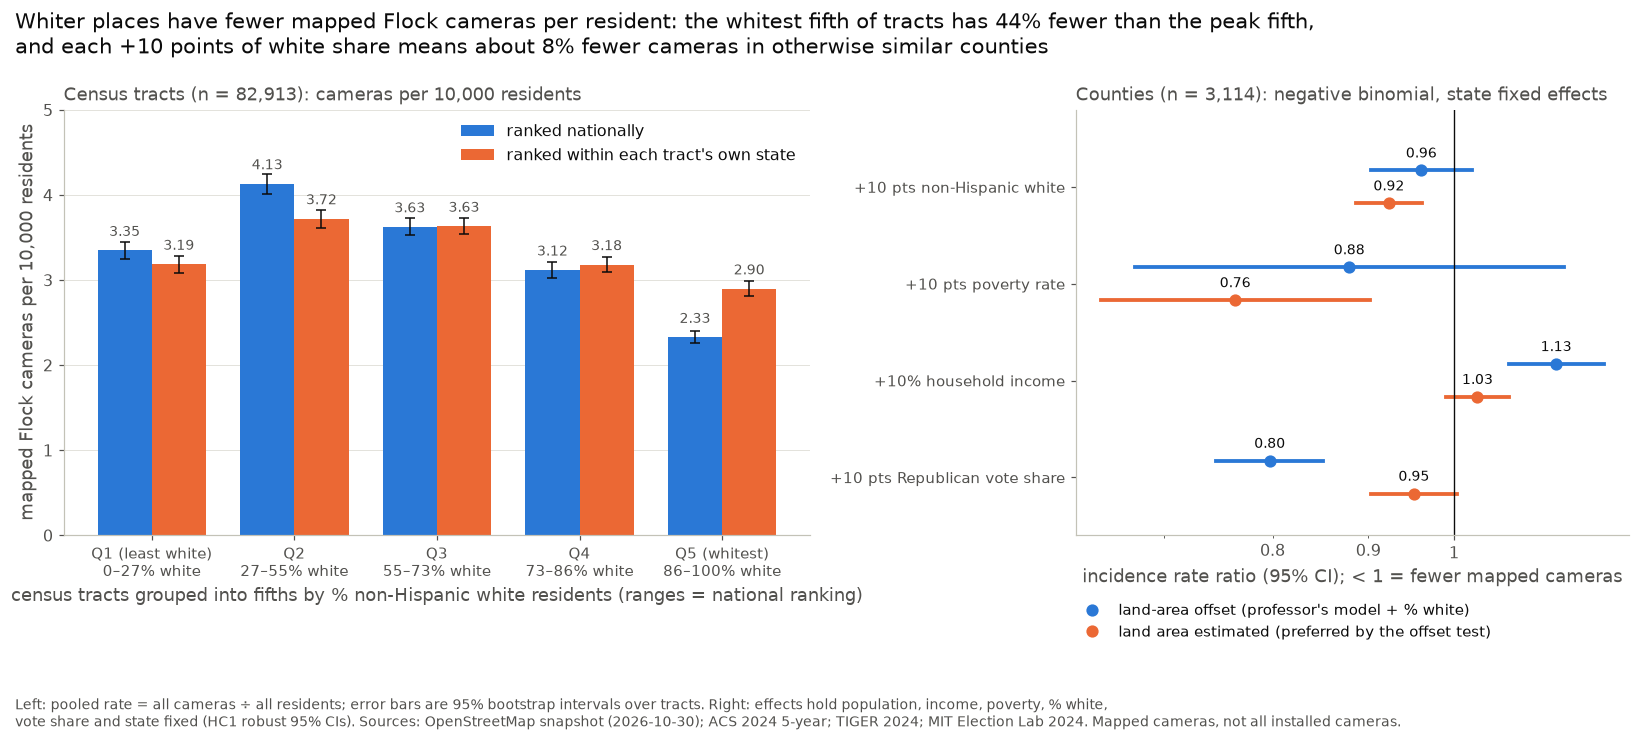

In [19]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.35, 1]})
x, wd = np.arange(1, 6), 0.38
for off, tab, col, lab in [(-wd / 2, race_nat, BLUE, "ranked nationally"),
                           (wd / 2, race_ws, ORANGE, "ranked within each tract's own state")]:
    ax.bar(x + off, tab["per_10k"], width=wd, color=col, label=lab, zorder=2)
    ax.errorbar(x + off, tab["per_10k"], yerr=[tab["per_10k"] - tab["ci_lo"], tab["ci_hi"] - tab["per_10k"]],
                fmt="none", ecolor=INK, capsize=3, linewidth=1, zorder=3)
    for xi, v in zip(x + off, tab["per_10k"]):
        ax.text(xi, v + 0.17, f"{v:.2f}", ha="center", fontsize=9, color=MUTED)
labels = [f"Q{r['q']}\n{r['min']:.0f}–{r['max']:.0f}% white" for r in race_nat.iter_rows(named=True)]
labels[0] = labels[0].replace("Q1", "Q1 (least white)")
labels[-1] = labels[-1].replace("Q5", "Q5 (whitest)")
ax.set_xticks(x, labels, fontsize=9.5)
ax.set_xlabel("census tracts grouped into fifths by % non-Hispanic white residents (ranges = national ranking)")
ax.set_ylabel("mapped Flock cameras per 10,000 residents")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, race_nat["ci_hi"].max() * 1.18)
ax.legend(frameon=False, loc="upper right")
ax.set_title(f"Census tracts (n = {elig.height:,}): cameras per 10,000 residents", loc="left", fontsize=11.5, color=MUTED)

# Right: county NB2 incidence rate ratios, professor's land-area offset (N5) vs land area estimated (N6).
FOREST = [("pct_white", "+10 pts non-Hispanic white"), ("poverty_rate", "+10 pts poverty rate"),
          ("log_income", "+10% household income"), ("gop_share_2024", "+10 pts Republican vote share")]
for off, m, col, lab in [(0.17, "N5", BLUE, "land-area offset (professor's model + % white)"),
                         (-0.17, "N6 N5", ORANGE, "land area estimated (preferred by the offset test)")]:
    for i, (t, _) in enumerate(FOREST):
        r = NB_TAB.filter(pl.col("model").str.starts_with(m) & (pl.col("term") == t)).row(0, named=True)
        yi = len(FOREST) - 1 - i + off
        bx.plot([r["per_lo"], r["per_hi"]], [yi, yi], color=col, linewidth=2.5)
        bx.plot(r["IRR_per"], yi, "o", color=col, markersize=7, label=lab if i == 0 else None)
        bx.text(r["IRR_per"], yi + 0.1, f"{r['IRR_per']:.2f}", ha="center", va="bottom", fontsize=9, color=INK,
                bbox=dict(fc="white", ec="none", pad=0.4))
bx.axvline(1, color=INK, linewidth=0.9)
bx.set_xscale("log")
bx.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
bx.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}" if v in (0.7, 0.8, 0.9, 1.1, 1.2) else ""))
bx.set_yticks(range(len(FOREST)), [lab for _, lab in FOREST][::-1], fontsize=10)
bx.set_ylim(-0.6, len(FOREST) - 0.2)
bx.grid(axis="y", visible=False)
bx.set_xlabel("incidence rate ratio (95% CI); < 1 = fewer mapped cameras")
bx.legend(frameon=False, loc="upper left", bbox_to_anchor=(-0.02, -0.13), fontsize=9.5)
bx.set_title(f"Counties (n = {len(nbd):,}): negative binomial, state fixed effects", loc="left", fontsize=11.5, color=MUTED)

w6 = RESULTS["nb_N6_pct_white"]
assert w6[2] < 1 and RESULTS["f2_white_q5"][2] < RESULTS["f2_peak_q"][3]  # title claims: CI below 1; tract CIs separate
fig.suptitle(f"Whiter places have fewer mapped Flock cameras per resident: the whitest fifth of tracts has "
             f"{RESULTS['f2_q5_vs_peak_pct_lower']:.0%} fewer than the peak fifth,\nand each +10 points of white share means about "
             f"{1 - w6[0]:.0%} fewer cameras in otherwise similar counties", x=0.01, ha="left", fontsize=13.5)
fig.text(0.01, -0.07, "Left: pooled rate = all cameras ÷ all residents; error bars are 95% bootstrap intervals over tracts. "
         "Right: effects hold population, income, poverty, % white,\nvote share and state fixed (HC1 robust 95% CIs). "
         "Sources: OpenStreetMap snapshot (2026-10-30); ACS 2024 5-year; TIGER 2024; MIT Election Lab 2024. "
         "Mapped cameras, not all installed cameras.", color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "finding-two.png", bbox_inches="tight")
plt.show()

---
## Finding 3: Political characteristics (Q3)

**Question.** Do counties that voted more Republican in 2024 have more or fewer mapped cameras per resident?

**Analysis.** This uses the county table and the negative binomial models built in Finding 2. We compare the vote
coefficient **before** adjustment (vote share alone) and **after** adjustment (population, income, poverty, % white and
state). We also keep dev3's linear model, OLS of log(1 + cameras per 10k) with HC1 robust standard errors, as a
second model family. Alaska and the territories have no county-level vote and are excluded.

In [20]:
print(f"county units {county.height:,} | analysed (vote + residents) {ana.height:,} | NB2 model counties {nbd.shape[0]:,}")

county units 3,234 | analysed (vote + residents) 3,115 | NB2 model counties 3,114


**Unadjusted associations.**

In [21]:
rho_all = stats.spearmanr(ana["rep_share"], ana["cameras_per_10k"])
pos = ana.filter(pl.col("cameras") > 0)
rho_pos = stats.spearmanr(pos["rep_share"], pos["cameras_per_10k"])
rho_size = stats.spearmanr(ana["rep_share"], ana["population"])
RESULTS["f3_n_counties"] = ana.height
RESULTS["f3_rho_all"] = (round(rho_all.statistic, 3), float(rho_all.pvalue))
RESULTS["f3_rho_with_camera"] = (round(rho_pos.statistic, 3), float(rho_pos.pvalue), pos.height)
RESULTS["f3_rho_vote_population"] = round(rho_size.statistic, 3)
print(f"Spearman rho, R share vs cameras per 10k: {rho_all.statistic:+.3f} (p = {rho_all.pvalue:.1g}, n = {ana.height:,})")
print(f"  counties with >= 1 camera only        : {rho_pos.statistic:+.3f} (p = {rho_pos.pvalue:.1g}, n = {pos.height:,})")
print(f"Spearman rho, R share vs population     : {rho_size.statistic:+.3f}")

Spearman rho, R share vs cameras per 10k: -0.095 (p = 9e-08, n = 3,115)
  counties with >= 1 camera only        : +0.130 (p = 7e-10, n = 2,250)
Spearman rho, R share vs population     : -0.529


In [22]:
def ols(y, X, names, w=None):
    # OLS (or WLS when w is given) with HC1 robust standard errors; numpy only.
    X = np.column_stack([np.ones(len(y)), X])
    if w is not None:
        sw = np.sqrt(w / w.mean())
        X, y = X * sw[:, None], y * sw
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ beta
    n, k = X.shape
    XtXi = np.linalg.pinv(X.T @ X)
    se = np.sqrt(np.diag(XtXi @ (X.T * e ** 2) @ X @ XtXi * n / (n - k)))
    return pl.DataFrame({"term": ["const", *names], "coef": beta, "se": se,
                         "ci_lo": beta - 1.96 * se, "ci_hi": beta + 1.96 * se}).slice(1, len(names))


m = ana.drop_nulls(["pct_nh_white", "income_pw", "pop_density"]).filter(
    pl.col("pop_density") > 0, *[pl.col(c).is_finite() for c in ["pct_nh_white", "income_pw", "pop_density", "rep_share"]])
y = np.log1p(m["cameras_per_10k"].to_numpy())
x_vote = (m["rep_share"].to_numpy() - 50) / 10                      # per 10 percentage points of Republican share
ctrl = np.column_stack([np.log(m["pop_density"].to_numpy()), m["pct_nh_white"].to_numpy() / 10, np.log(m["income_pw"].to_numpy())])
fe = pd.get_dummies(m["state"].to_pandas(), drop_first=True).to_numpy(float)
fe_names = [f"fe{i}" for i in range(fe.shape[1])]
full = ["R share (+10 pts)", "log pop density", "% NH white (+10 pts)", "log income"]
MODELS = {
    "A: vote only": (x_vote[:, None], ["R share (+10 pts)"], None),
    "B: + state fixed effects": (np.column_stack([x_vote, fe]), ["R share (+10 pts)"] + fe_names, None),
    "C: + density, % white, income": (np.column_stack([x_vote, ctrl, fe]), full + fe_names, None),
    "D: model C, weighted by population": (np.column_stack([x_vote, ctrl, fe]), full + fe_names, m["population"].to_numpy()),
}
res = pl.concat([ols(y, X, names, w).filter(~pl.col("term").str.starts_with("fe")).with_columns(pl.lit(k).alias("model"))
                 for k, (X, names, w) in MODELS.items()])
vote = res.filter(pl.col("term") == "R share (+10 pts)")
RESULTS["f3_model_n"] = m.height
RESULTS["f3_vote_coef"] = {r["model"]: tuple(round(r[c], 3) for c in ("coef", "ci_lo", "ci_hi")) for r in vote.iter_rows(named=True)}
RESULTS["f3_model_C_other"] = {r["term"]: tuple(round(r[c], 3) for c in ("coef", "ci_lo", "ci_hi"))
                               for r in res.filter((pl.col("model") == "C: + density, % white, income") & (pl.col("term") != "R share (+10 pts)")).iter_rows(named=True)}
print(f"outcome: log(1 + cameras per 10k), n = {m.height:,} counties; 95% CIs from HC1 robust SEs")
res.select("model", "term", pl.col("coef", "se", "ci_lo", "ci_hi").round(3))

outcome: log(1 + cameras per 10k), n = 3,114 counties; 95% CIs from HC1 robust SEs


model,term,coef,se,ci_lo,ci_hi
str,str,f64,f64,f64,f64
"""A: vote only""","""R share (+10 pts)""",-0.028,0.01,-0.048,-0.007
"""B: + state fixed effects""","""R share (+10 pts)""",-0.07,0.011,-0.091,-0.048
"""C: + density, % white, income""","""R share (+10 pts)""",0.007,0.018,-0.029,0.042
"""C: + density, % white, income""","""log pop density""",0.02,0.018,-0.015,0.056
"""C: + density, % white, income""","""% NH white (+10 pts)""",-0.056,0.014,-0.084,-0.027
"""C: + density, % white, income""","""log income""",0.658,0.081,0.499,0.818
"""D: model C, weighted by popula…","""R share (+10 pts)""",-0.014,0.021,-0.054,0.027
"""D: model C, weighted by popula…","""log pop density""",-0.032,0.019,-0.07,0.006
"""D: model C, weighted by popula…","""% NH white (+10 pts)""",-0.02,0.019,-0.058,0.018


**Negative binomial: unadjusted vs adjusted vote coefficient.** Same NB2 models as in Finding 2. N1 and N2 are
unadjusted (vote share only, per square mile and per resident); N3 adds state fixed effects; N4 is the professor's
model; N5 adds % white; N6 estimates the land-area coefficient instead of fixing it; N7 uses a population offset; N8
drops state fixed effects. IRR per +10 points of Republican share.

In [23]:
VOTE_NB = (NB_TAB.filter(pl.col("term") == "gop_share_2024")
                 .select("model", pl.col("IRR_per", "per_lo", "per_hi").round(3), pl.col("p").map_elements(lambda v: f"{v:.2g}", return_dtype=pl.String)))
print(VOTE_NB)

shape: (9, 5)
┌─────────────────────────────────┬─────────┬────────┬────────┬──────────┐
│ model                           ┆ IRR_per ┆ per_lo ┆ per_hi ┆ p        │
│ ---                             ┆ ---     ┆ ---    ┆ ---    ┆ ---      │
│ str                             ┆ f64     ┆ f64    ┆ f64    ┆ str      │
╞═════════════════════════════════╪═════════╪════════╪════════╪══════════╡
│ N1 unadjusted, per sq mi        ┆ 0.485   ┆ 0.464  ┆ 0.507  ┆ 8.5e-227 │
│ N2 unadjusted, per resident     ┆ 1.008   ┆ 0.979  ┆ 1.037  ┆ 0.59     │
│ N3 state FE only, per resident  ┆ 0.906   ┆ 0.877  ┆ 0.936  ┆ 2.1e-09  │
│ N4 professor's model (land off… ┆ 0.775   ┆ 0.726  ┆ 0.827  ┆ 1.7e-14  │
│ N5 N4 + % white (land offset)   ┆ 0.797   ┆ 0.746  ┆ 0.852  ┆ 1.8e-11  │
│ N6 N5 with land area estimated  ┆ 0.952   ┆ 0.903  ┆ 1.004  ┆ 0.069    │
│ N7 population offset (per resi… ┆ 0.952   ┆ 0.903  ┆ 1.004  ┆ 0.067    │
│ N8 N6 without state FE          ┆ 1.171   ┆ 1.126  ┆ 1.217  ┆ 2.1e-15  │
│ N6 cluste

**Alternative explanation: county size.** Strongly Republican counties are mostly small and rural, so any raw vote
pattern could really be a size pattern. Checks: (1) model C above adds density, composition, income and state.
(2) Model D weights by population so small counties cannot dominate. (3) The table below pools density by vote band
within county-size bands.

In [24]:
VOTE_LABELS = ["< 40%", "40–50%", "50–60%", "60–70%", "≥ 70%"]
size = ana.with_columns(pl.col("rep_share").cut([40, 50, 60, 70], labels=VOTE_LABELS, left_closed=True).alias("vote_band"),
                        pl.col("population").cut([25_000, 100_000, 500_000], labels=["< 25k", "25k–100k", "100k–500k", "≥ 500k"]).alias("size"))
size_tab = (size.group_by("size", "vote_band").agg((pl.col("cameras").sum() / pl.col("population").sum() * 1e4).round(2).alias("r"))
                .pivot(on="vote_band", index="size", values="r").select("size", *VOTE_LABELS).sort("size"))
print("pooled cameras per 10k residents: county population band (rows) x 2024 Republican two-party share (columns)")
size_tab

pooled cameras per 10k residents: county population band (rows) x 2024 Republican two-party share (columns)


size,< 40%,40–50%,50–60%,60–70%,≥ 70%
enum,f64,f64,f64,f64,f64
"""< 25k""",3.64,2.63,2.96,2.86,2.77
"""25k–100k""",3.65,2.66,2.86,3.31,3.28
"""100k–500k""",3.37,3.11,3.64,3.73,3.9
"""≥ 500k""",3.02,3.82,3.47,3.29,3.49


### Figure 3

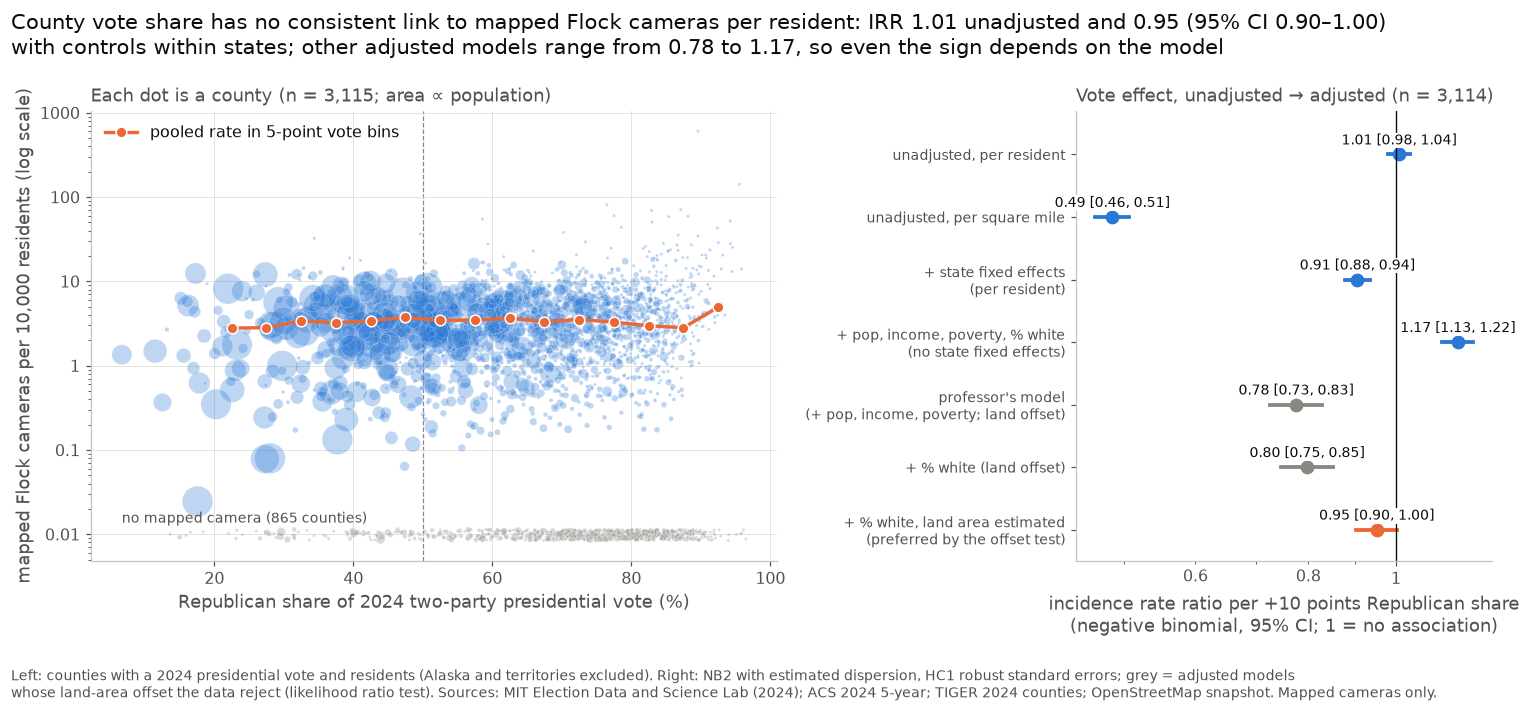

In [25]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.65, 1]})
# Left: V8 scatter (dot area ~ population; zero-camera counties drawn on a strip at the bottom of the log axis).
pos, zero = ana.filter(pl.col("cameras") > 0), ana.filter(pl.col("cameras") == 0)
floor = pos["cameras_per_10k"].min() / 2.5
size_of = lambda d: np.clip(d["population"].to_numpy() / 4000, 4, 400)
rng = np.random.default_rng(418)
ax.scatter(pos["rep_share"], pos["cameras_per_10k"], s=size_of(pos), color=BLUE, alpha=0.3, edgecolor="white", linewidth=0.4, zorder=2)
ax.scatter(zero["rep_share"], floor * np.exp(rng.uniform(-0.15, 0.15, zero.height)), s=size_of(zero), color=GREY, alpha=0.3,
           edgecolor="white", linewidth=0.4, zorder=2)
ax.text(ana["rep_share"].min(), floor * 1.4, f"no mapped camera ({zero.height:,} counties)", color=MUTED, fontsize=9)
bins = (ana.with_columns((pl.col("rep_share") // 5 * 5 + 2.5).alias("mid")).group_by("mid")
           .agg((pl.col("cameras").sum() / pl.col("population").sum() * 1e4).alias("r"), pl.len().alias("n"))
           .filter(pl.col("n") >= 20).sort("mid"))
ax.plot(bins["mid"], bins["r"], color=ORANGE, linewidth=2.2, marker="o", markersize=7, markeredgecolor="white", zorder=4,
        label="pooled rate in 5-point vote bins")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.axvline(50, color=GREY, linewidth=0.8, linestyle="--", zorder=1)
ax.set_xlabel("Republican share of 2024 two-party presidential vote (%)")
ax.set_ylabel("mapped Flock cameras per 10,000 residents (log scale)")
ax.legend(frameon=False, loc="upper left")
ax.set_title(f"Each dot is a county (n = {ana.height:,}; area ∝ population)", loc="left", fontsize=11.5, color=MUTED)

# Right: the vote-share IRR from unadjusted to adjusted NB2 models, with 95% robust CIs.
ROWS3 = [("N2", "unadjusted, per resident"), ("N1", "unadjusted, per square mile"), ("N3", "+ state fixed effects\n(per resident)"),
         ("N8", "+ pop, income, poverty, % white\n(no state fixed effects)"),
         ("N4", "professor's model\n(+ pop, income, poverty; land offset)"), ("N5", "+ % white (land offset)"),
         ("N6 N5", "+ % white, land area estimated\n(preferred by the offset test)")]
for i, (k, lab) in enumerate(ROWS3):
    r = NB_TAB.filter(pl.col("model").str.starts_with(k) & (pl.col("term") == "gop_share_2024")).row(0, named=True)
    yi = len(ROWS3) - 1 - i
    c = ORANGE if k == "N6 N5" else (GREY if k in ("N4", "N5") else BLUE)
    bx.plot([r["per_lo"], r["per_hi"]], [yi, yi], color=c, linewidth=2.5)
    bx.plot(r["IRR_per"], yi, "o", color=c, markersize=8)
    bx.text(r["IRR_per"], yi + 0.16, f"{r['IRR_per']:.2f} [{r['per_lo']:.2f}, {r['per_hi']:.2f}]", ha="center", fontsize=9, color=INK,
            bbox=dict(fc="white", ec="none", pad=0.4))
bx.axvline(1, color=INK, linewidth=0.9)
bx.set_xscale("log")
bx.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
bx.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}" if round(v, 1) in (0.4, 0.6, 0.8, 1.2) else ""))
bx.set_yticks(range(len(ROWS3)), [lab for _, lab in ROWS3][::-1], fontsize=9)
bx.set_ylim(-0.5, len(ROWS3) - 0.3)
bx.grid(axis="y", visible=False)
bx.set_xlabel("incidence rate ratio per +10 points Republican share\n(negative binomial, 95% CI; 1 = no association)")
bx.set_title(f"Vote effect, unadjusted → adjusted (n = {len(nbd):,})", loc="left", fontsize=11.5, color=MUTED)

v2, v6, v8 = RESULTS["nb_N2_gop_share_2024"], RESULTS["nb_N6_gop_share_2024"], RESULTS["nb_N8_gop_share_2024"]
assert v2[1] < 1 < v2[2] and v6[1] < 1 < v6[2]  # title claims: both CIs include 1
fig.suptitle(f"County vote share has no consistent link to mapped Flock cameras per resident: IRR {v2[0]:.2f} unadjusted and "
             f"{v6[0]:.2f} (95% CI {v6[1]:.2f}–{v6[2]:.2f})\nwith controls within states; other adjusted models range from "
             f"{RESULTS['nb_N4_gop_share_2024'][0]:.2f} to {v8[0]:.2f}, so even the sign depends on the model", x=0.01, ha="left", fontsize=13.5)
fig.text(0.01, -0.06, f"Left: counties with a 2024 presidential vote and residents (Alaska and territories excluded). Right: NB2 "
         "with estimated dispersion, HC1 robust standard errors; grey = adjusted models\nwhose land-area offset the data reject (likelihood ratio test). Sources: MIT "
         "Election Data and Science Lab (2024); ACS 2024 5-year; TIGER 2024 counties; OpenStreetMap snapshot. Mapped cameras only.",
         color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "finding-three.png", bbox_inches="tight")
plt.show()

---
## Every number used in the README

In [26]:
for k, v in RESULTS.items():
    print(f"{k:36s} {v}")
for f in ["finding-one.png", "finding-two.png", "finding-three.png"]:
    p = FIG / f
    print(f"{f}: exists={p.exists()} size={p.stat().st_size / 1e3:.0f} kB")

f1_total_dated                       112522
f1_first_month                       2024-11-01
f1_first_month_new                   514
f1_2026_new                          68899
f1_2026_share                        0.6123158137964132
f1_jun2025_cumulative                12139
f1_pre_monthly_range                 (514, 2401)
f1_peak_months                       [('2026-07-01', 11457), ('2026-08-01', 11807)]
f1_peak_total                        23264
f1_peak_changesets                   22599
f1_peak_contributors_v1              9243
f1_peak_retag_share                  0.013970082530949106
f1_peak_bulk_share                   0.0
f1_all_bulk_share                    0.010966744281118358
f1_all_retag_share                   0.03444659710989851
f1_max_changeset                     430
f1_earliest_tag                      2024-11-03
f1_created_before_nov2024            657
f1_created_before_and_tagged_later   657
f1_counties_reached                  2279
f1_end2025_counties_share            